In [1]:
import pandas as pd

# Load the bank dataset
df = pd.read_csv('/content/bank.csv', sep=None, engine='python')

# Display overall info and structure
print(df.info())
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB
None


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Map target variable 'deposit' to binary 1 (yes) and 0 (no)
y = df['deposit'].map({'yes': 1, 'no': 0})

# Select the specific features requested
feature_cols = ['contact', 'poutcome', 'job', 'age', 'duration']
X = df[feature_cols]

# Identify categorical and numerical features
categorical_features = ['contact', 'poutcome', 'job']
numerical_features = ['age', 'duration']

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Complete classification pipeline with Random Forest
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, n_estimators=100, class_weight='balanced'))
])

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Train the model
model_pipeline.fit(X_train, y_train)

# Predictions
y_pred = model_pipeline.predict(X_test)
y_probs = model_pipeline.predict_proba(X_test)[:, 1]

# Evaluation Metrics
print("Classification Report:")
print(classification_report(y_test, y_pred))

roc_auc = roc_auc_score(y_test, y_probs)
print(f"ROC-AUC Score: {roc_auc:.4f}")

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.79      0.80      1175
           1       0.77      0.78      0.77      1058

    accuracy                           0.79      2233
   macro avg       0.78      0.79      0.79      2233
weighted avg       0.79      0.79      0.79      2233

ROC-AUC Score: 0.8539


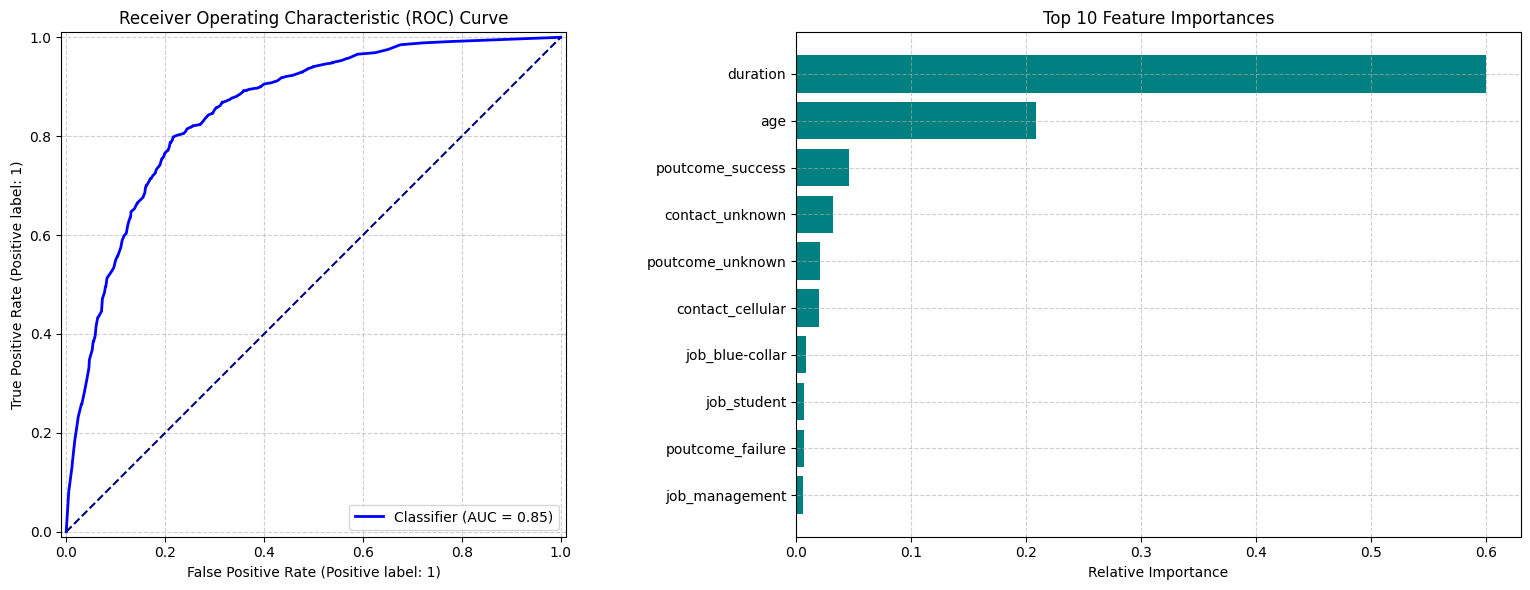

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, RocCurveDisplay

# Calculate ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_probs)

# Get feature importances from random forest
classifier = model_pipeline.named_steps['classifier']
encoded_features = (
    numerical_features +
    list(model_pipeline.named_steps['preprocessor']
         .named_transformers_['cat']
         .get_feature_names_out(categorical_features))
)
importances = classifier.feature_importances_
indices = np.argsort(importances)[::-1]

# Plotting ROC Curve and Feature Importances
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: ROC Curve
RocCurveDisplay.from_predictions(y_test, y_probs, ax=ax1, color='blue', lw=2)
ax1.plot([0, 1], [0, 1], color='navy', linestyle='--')
ax1.set_title('Receiver Operating Characteristic (ROC) Curve')
ax1.grid(True, linestyle='--', alpha=0.6)

# Plot 2: Feature Importances (Top 10)
top_n = 10
ax2.barh(range(top_n), importances[indices[:top_n]][::-1], align='center', color='teal')
ax2.set_yticks(range(top_n))
ax2.set_yticklabels([encoded_features[i] for i in indices[:top_n]][::-1])
ax2.set_xlabel('Relative Importance')
ax2.set_title('Top 10 Feature Importances')
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()